<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_04_RidgeRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Exact path to your processed folder
path = "/content/drive/MyDrive/DemandLens/Data/"
OUT_PROCESSED = path + "processed/"
OUT_TESTING   = path + "Testing/"

In [ ]:
# 1. Load 7-Day Horizon Train, Test & Validation Datasets
train_7  = pd.read_parquet(f"{OUT_PROCESSED}ca1_h7_train.parquet")
val_7    = pd.read_parquet(f"{OUT_PROCESSED}ca1_h7_val.parquet")
test_7   = pd.read_parquet(f"{OUT_TESTING}ca1_h7_test.parquet")

In [ ]:
# 2. Load 28-Day Horizon Train, Test & Validation Datasets
train_28 = pd.read_parquet(f"{OUT_PROCESSED}ca1_h28_train.parquet")
val_28   = pd.read_parquet(f"{OUT_PROCESSED}ca1_h28_val.parquet")
test_28  = pd.read_parquet(f"{OUT_TESTING}ca1_h28_test.parquet")

In [ ]:
train_7.shape, val_7.shape, test_7.shape

((4552041, 26), (85372, 26), (85372, 26))

In [ ]:
train_28.shape, val_28.shape, test_28.shape

((4424067, 26), (85359, 26), (85372, 26))

In [ ]:
pd.set_option("display.max_columns", None)

In [ ]:
train_7.head()

,item_id,store_id,date,sales,lag_7,rolling_mean_7,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-02-09,0,4.0,1.600000,5,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-02-10,3,2.0,1.666667,6,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-02-11,1,0.0,1.428571,7,2,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-02-12,3,2.0,1.285714,1,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-02-13,0,0.0,1.285714,2,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [ ]:
train_28.head()

,item_id,store_id,date,sales,lag_28,rolling_mean_28,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-03-23,1,2.0,1.269231,5,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-03-24,0,2.0,1.296296,6,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-03-25,1,4.0,1.392857,7,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-03-26,2,2.0,1.357143,1,3,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-03-27,2,2.0,1.428571,2,3,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [ ]:
corr_cols_7  = ["sales", "lag_7", "rolling_mean_7", "sell_price", "price_change",
                "is_weekend", "has_event", "snap", "wday", "month", "year"]
corr_cols_28 = ["sales", "lag_28", "rolling_mean_28", "sell_price", "price_change",
                "is_weekend", "has_event", "snap", "wday", "month", "year"]

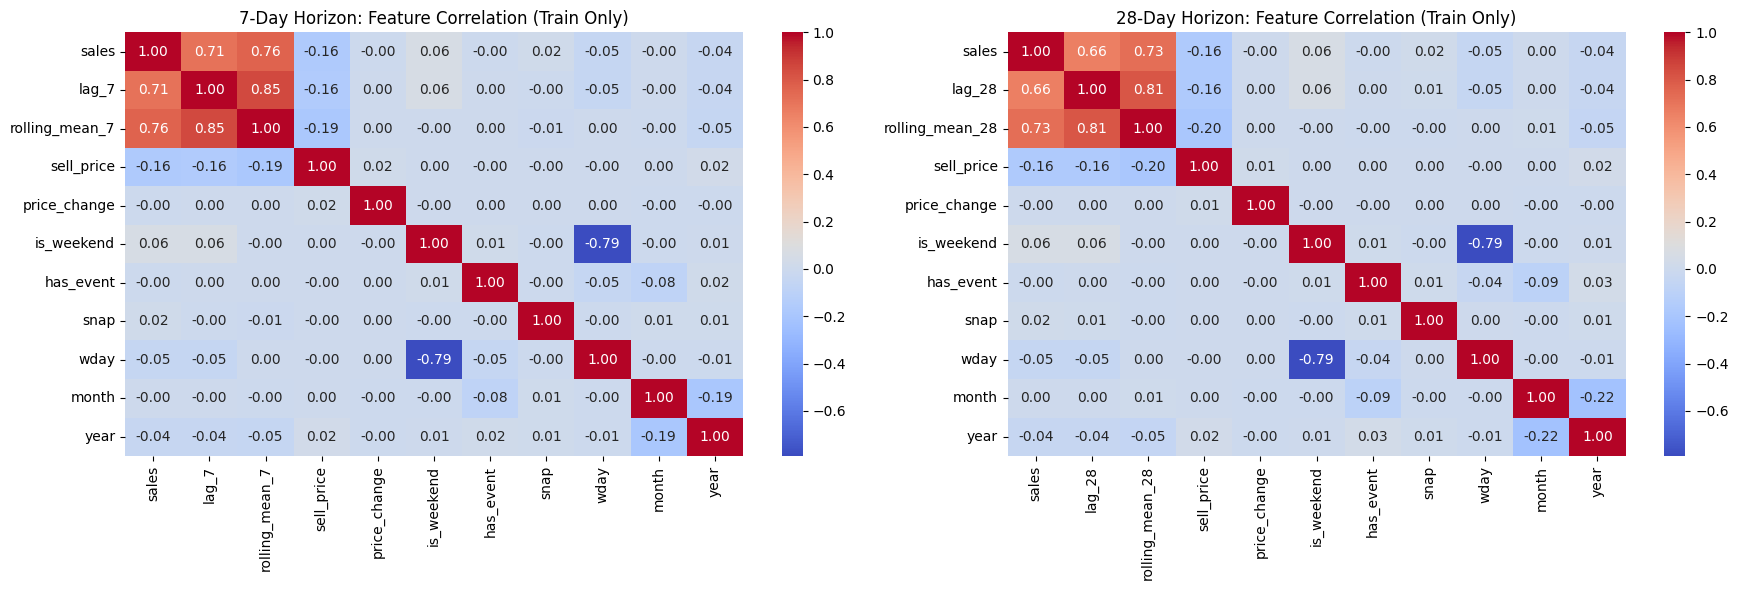

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# 7-Day Train Correlation
sns.heatmap(train_7[corr_cols_7].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("7-Day Horizon: Feature Correlation (Train Only)")
# 28-Day Train Correlation
sns.heatmap(train_28[corr_cols_28].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("28-Day Horizon: Feature Correlation (Train Only)")
plt.tight_layout()
plt.show()

In [ ]:
drop_cols = ["item_id", "store_id", "date", "sales", "ev_None", "dept_HOUSEHOLD_2"]

### Feature Selection Note: Dropping `ev_None` and `dept_HOUSEHOLD_2`

* **Preventing the Dummy Variable Trap:** One-hot encoded groups always sum to `1` across every row (each day has one event status, and each product belongs to one department). Keeping all columns creates exact multicollinearity with the linear model's intercept.
* **Setting a Reference Baseline:** Dropping `ev_None` and `dept_HOUSEHOLD_2` removes this linear redundancy without losing any information. When all remaining columns in a group equal `0`, the model treats that row as the baseline category (`ev_None` or `dept_HOUSEHOLD_2`).
* **Model-Specific Preprocessing:** Tree-based models (Decision Tree, Random Forest, LightGBM) split more efficiently when all dummy columns are present, so all columns are retained in the shared `processed/` Parquet files and only dropped here for Ridge Regression.

In [ ]:
# 7-Day Horizon
X_train_7 = train_7.drop(columns=drop_cols)
y_train_7 = train_7["sales"]

X_val_7   = val_7.drop(columns=drop_cols)
y_val_7   = val_7["sales"]

X_test_7  = test_7.drop(columns=drop_cols)
y_test_7  = test_7["sales"]

In [ ]:
X_train_7.shape, y_train_7.shape

((4552041, 20), (4552041,))

In [ ]:
# 28-Day Horizon
X_train_28 = train_28.drop(columns=drop_cols)
y_train_28 = train_28["sales"]

X_val_28   = val_28.drop(columns=drop_cols)
y_val_28   = val_28["sales"]

X_test_28  = test_28.drop(columns=drop_cols)
y_test_28  = test_28["sales"]

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
num_cols_7  = ["lag_7", "rolling_mean_7", "wday", "month", "year", "sell_price", "price_change"]
num_cols_28 = ["lag_28", "rolling_mean_28", "wday", "month", "year", "sell_price", "price_change"]

In [ ]:
# 7-Day Horizon Scaling (fit ONLY on X_train_7)
scaler_7 = StandardScaler()
X_train_7[num_cols_7] = scaler_7.fit_transform(X_train_7[num_cols_7])
X_val_7[num_cols_7]   = scaler_7.transform(X_val_7[num_cols_7])
X_test_7[num_cols_7]  = scaler_7.transform(X_test_7[num_cols_7])

In [ ]:
# 28-Day Horizon Scaling (fit ONLY on X_train_28)
scaler_28 = StandardScaler()
X_train_28[num_cols_28] = scaler_28.fit_transform(X_train_28[num_cols_28])
X_val_28[num_cols_28]   = scaler_28.transform(X_val_28[num_cols_28])
X_test_28[num_cols_28]  = scaler_28.transform(X_test_28[num_cols_28])

In [ ]:
# 4. Save scaled test sets (with IDs and target) to Testing/ folder
test_7_scaled_out  = pd.concat([test_7[["item_id", "store_id", "date", "sales"]], X_test_7], axis=1)
test_28_scaled_out = pd.concat([test_28[["item_id", "store_id", "date", "sales"]], X_test_28], axis=1)
test_7_scaled_out.to_parquet(f"{OUT_TESTING}ca1_h7_test_scaled_lr.parquet", index=False)
test_28_scaled_out.to_parquet(f"{OUT_TESTING}ca1_h28_test_scaled_lr.parquet", index=False)

In [ ]:
import gc

In [ ]:
del test_7, test_28, X_test_7, X_test_28, y_test_7, y_test_28, test_7_scaled_out, test_28_scaled_out
gc.collect()

39

In [ ]:
X_train_7.shape, X_val_7.shape

((4552041, 20), (85372, 20))

In [ ]:
X_train_28.shape, X_val_28.shape

((4424067, 20), (85359, 20))

In [ ]:
X_train_7.head()

,lag_7,rolling_mean_7,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1
0,0.524387,-0.012102,0.502961,-1.285799,-1.721466,0,1,0,-0.710582,-0.005448,0,0,0,0,1,0,0,0,0,0
1,0.078827,0.005181,1.002678,-1.285799,-1.721466,0,1,0,-0.710582,-0.005448,0,0,0,0,1,0,0,0,0,0
2,-0.366734,-0.056545,1.502395,-1.285799,-1.721466,0,0,0,-0.710582,-0.005448,0,0,0,0,1,0,0,0,0,0
3,0.078827,-0.093581,-1.495907,-1.285799,-1.721466,1,0,0,-0.710582,-0.005448,0,0,0,0,1,0,0,0,0,0
4,-0.366734,-0.093581,-0.996190,-1.285799,-1.721466,1,0,0,-0.710582,-0.005448,0,0,0,0,1,0,0,0,0,0


In [ ]:
X_train_28.head()

,lag_28,rolling_mean_28,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1
0,0.078531,-0.102612,0.503049,-1.016046,-1.778686,0,0,0,-0.711321,-0.004834,0,0,0,0,1,0,0,0,0,0
1,0.078531,-0.095308,1.002761,-1.016046,-1.778686,0,0,0,-0.711321,-0.004834,0,0,0,0,1,0,0,0,0,0
2,0.523611,-0.069248,1.502474,-1.016046,-1.778686,0,0,0,-0.711321,-0.004834,0,0,0,0,1,0,0,0,0,0
3,0.078531,-0.078887,-1.495801,-1.016046,-1.778686,1,0,0,-0.711321,-0.004834,0,0,0,0,1,0,0,0,0,0
4,0.078531,-0.059609,-0.996089,-1.016046,-1.778686,1,0,0,-0.711321,-0.004834,0,0,0,0,1,0,0,0,0,0


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [ ]:
# Function to calculate forecast performance
def evaluate_forecast(y_true, y_pred):

    # Predictions cannot be negative because sales cannot be negative
    y_pred = np.maximum(y_pred, 0)

    # Calculate WAPE, MAE and RMSE
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    return {
        "WAPE (%)": round(wape, 2),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    }

In [ ]:
# Evaluate 7-day and 28-day naive forecasts
base_7 = evaluate_forecast(y_val_7, val_7["lag_7"])
base_28 = evaluate_forecast(y_val_28, val_28["lag_28"])

In [ ]:
# Display results
print("7-Day Baseline:", base_7)
print("28-Day Baseline:", base_28)

7-Day Baseline: {'WAPE (%)': np.float64(87.38), 'MAE': 1.3097, 'RMSE': 2.8066}
28-Day Baseline: {'WAPE (%)': np.float64(89.31), 'MAE': 1.3386, 'RMSE': 2.8627}


### Baseline Benchmark: Seasonal Naive Forecast (`lag_7` & `lag_28`)

Before evaluating Ridge Regression, we establish a **Seasonal Naive Baseline** as our minimum performance benchmark:
* **7-Day Horizon Baseline (`lag_7`):** Predicts that today's unit sales will equal the exact sales recorded **7 days ago** (same day last week).
* **28-Day Horizon Baseline (`lag_28`):** Predicts that today's unit sales will equal the exact sales recorded **28 days ago** (same day 4 weeks ago).

**Why this benchmark matters:**
* **Zero-Training Reference:** A naive forecast requires no machine learning—it simply carries forward historical same-weekday demand.
* **Proving Real Predictive Value:** In retail time-series forecasting, achieving a low error metric alone does not guarantee a useful model. Our Ridge Regression model must noticeably beat the Naive Baseline's **WAPE, MAE, and RMSE** on the validation set to prove that combining rolling averages, pricing changes, calendar seasonality, and special events adds genuine predictive signal beyond simple lag repetition.

In [ ]:
# Try different alpha values
alphas = [0.01, 0.1, 1, 10, 50, 100, 500, 1000]

In [ ]:
results_7 = []
results_28 = []

In [ ]:
# Test different alpha values for 7-day and 28-day Ridge models
for alpha in alphas:

    # 7-Day Ridge Model
    model_7 = Ridge(alpha=alpha)
    model_7.fit(X_train_7, y_train_7)

    predictions_7 = model_7.predict(X_val_7)
    scores_7 = evaluate_forecast(y_val_7, predictions_7)

    results_7.append({"alpha": alpha, **scores_7})


    # 28-Day Ridge Model
    model_28 = Ridge(alpha=alpha)
    model_28.fit(X_train_28, y_train_28)

    predictions_28 = model_28.predict(X_val_28)
    scores_28 = evaluate_forecast(y_val_28, predictions_28)

    results_28.append({"alpha": alpha, **scores_28})

In [ ]:
# Convert results into DataFrames and sort by WAPE
df_tune_7 = pd.DataFrame(results_7).sort_values("WAPE (%)")
df_tune_28 = pd.DataFrame(results_28).sort_values("WAPE (%)")

In [ ]:
df_tune_7

,alpha,WAPE (%),MAE,RMSE
0,0.01,75.72,1.1349,2.2519
1,0.10,75.72,1.1349,2.2519
2,1.00,75.72,1.1349,2.2519
3,10.00,75.72,1.1349,2.2519
4,50.00,75.72,1.1349,2.2519
5,100.00,75.72,1.1349,2.2519
6,500.00,75.72,1.1349,2.2519
7,1000.00,75.72,1.1349,2.2519


In [ ]:
df_tune_28

,alpha,WAPE (%),MAE,RMSE
0,0.01,76.5,1.1465,2.2645
1,0.10,76.5,1.1465,2.2645
2,1.00,76.5,1.1465,2.2645
3,10.00,76.5,1.1465,2.2645
4,50.00,76.5,1.1465,2.2645
5,100.00,76.5,1.1465,2.2645
6,500.00,76.5,1.1465,2.2645
7,1000.00,76.5,1.1466,2.2645


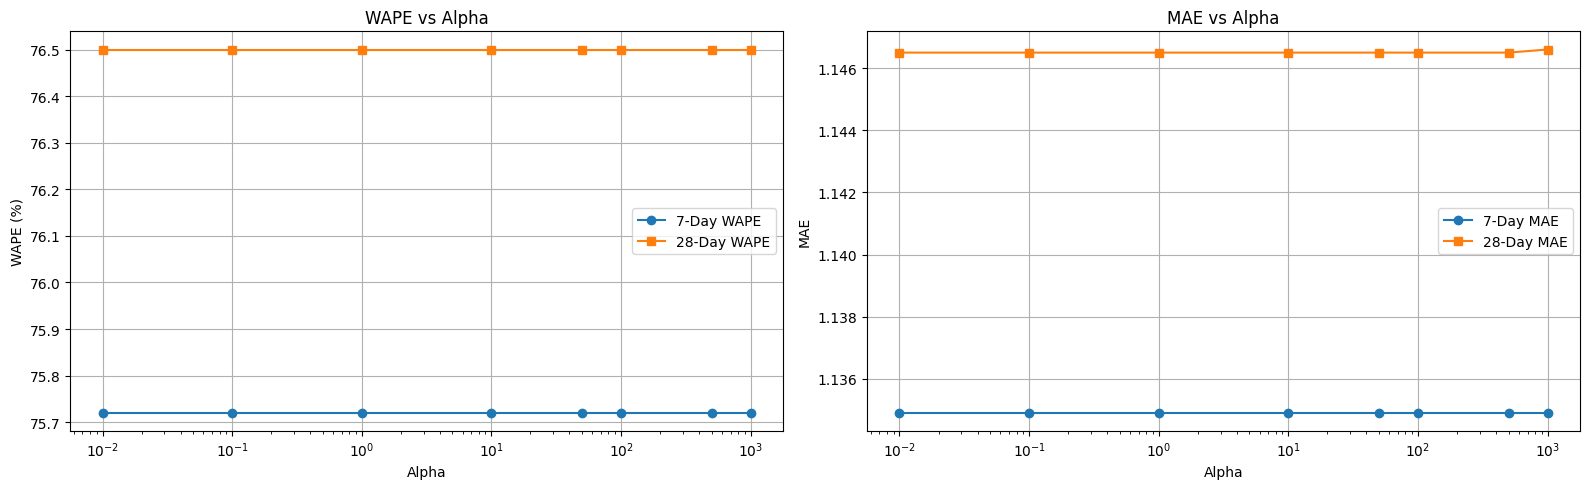

In [ ]:
# Sort results by alpha
df_7_sorted = df_tune_7.sort_values("alpha")
df_28_sorted = df_tune_28.sort_values("alpha")

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot WAPE for both models
axes[0].plot(df_7_sorted["alpha"], df_7_sorted["WAPE (%)"], marker="o", label="7-Day WAPE")
axes[0].plot(df_28_sorted["alpha"], df_28_sorted["WAPE (%)"], marker="s", label="28-Day WAPE")

axes[0].set_xscale("log")
axes[0].set_title("WAPE vs Alpha")
axes[0].set_xlabel("Alpha")
axes[0].set_ylabel("WAPE (%)")
axes[0].grid()
axes[0].legend()

# Plot MAE for both models
axes[1].plot(df_7_sorted["alpha"], df_7_sorted["MAE"], marker="o", label="7-Day MAE")
axes[1].plot(df_28_sorted["alpha"], df_28_sorted["MAE"], marker="s", label="28-Day MAE")

axes[1].set_xscale("log")
axes[1].set_title("MAE vs Alpha")
axes[1].set_xlabel("Alpha")
axes[1].set_ylabel("MAE")
axes[1].grid()
axes[1].legend()

# Display both plots
plt.tight_layout()
plt.show()

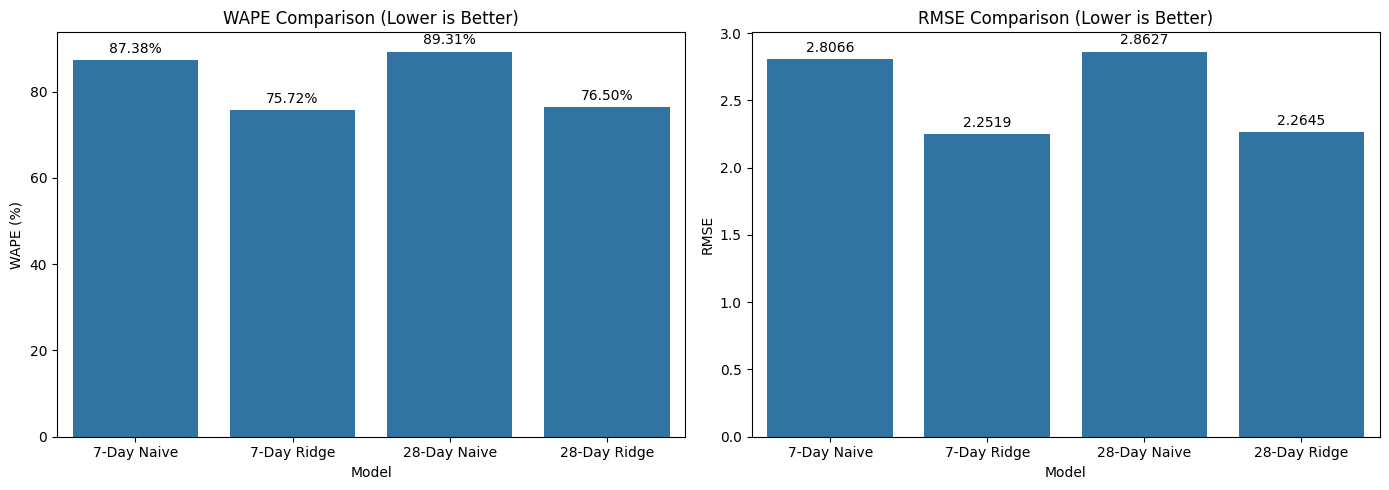

In [ ]:
# Compare Naive Baseline and Ridge Regression
comp_df = pd.DataFrame({
    "Model": ["7-Day Naive", "7-Day Ridge", "28-Day Naive", "28-Day Ridge"],

    "WAPE (%)": [
        87.38,
        df_7_sorted[df_7_sorted["alpha"] == 100]["WAPE (%)"].values[0],
        89.31,
        df_28_sorted[df_28_sorted["alpha"] == 100]["WAPE (%)"].values[0]
    ],

    "RMSE": [
        2.8066,
        df_7_sorted[df_7_sorted["alpha"] == 100]["RMSE"].values[0],
        2.8627,
        df_28_sorted[df_28_sorted["alpha"] == 100]["RMSE"].values[0]
    ]
})
# Create two bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# WAPE comparison
sns.barplot(data=comp_df, x="Model", y="WAPE (%)", ax=axes[0])
axes[0].set_title("WAPE Comparison (Lower is Better)")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f%%", padding=3)

# RMSE comparison
sns.barplot(data=comp_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE Comparison (Lower is Better)")
axes[1].bar_label(axes[1].containers[0], fmt="%.4f", padding=3)
# Adjust layout and display charts
plt.tight_layout()
plt.show()

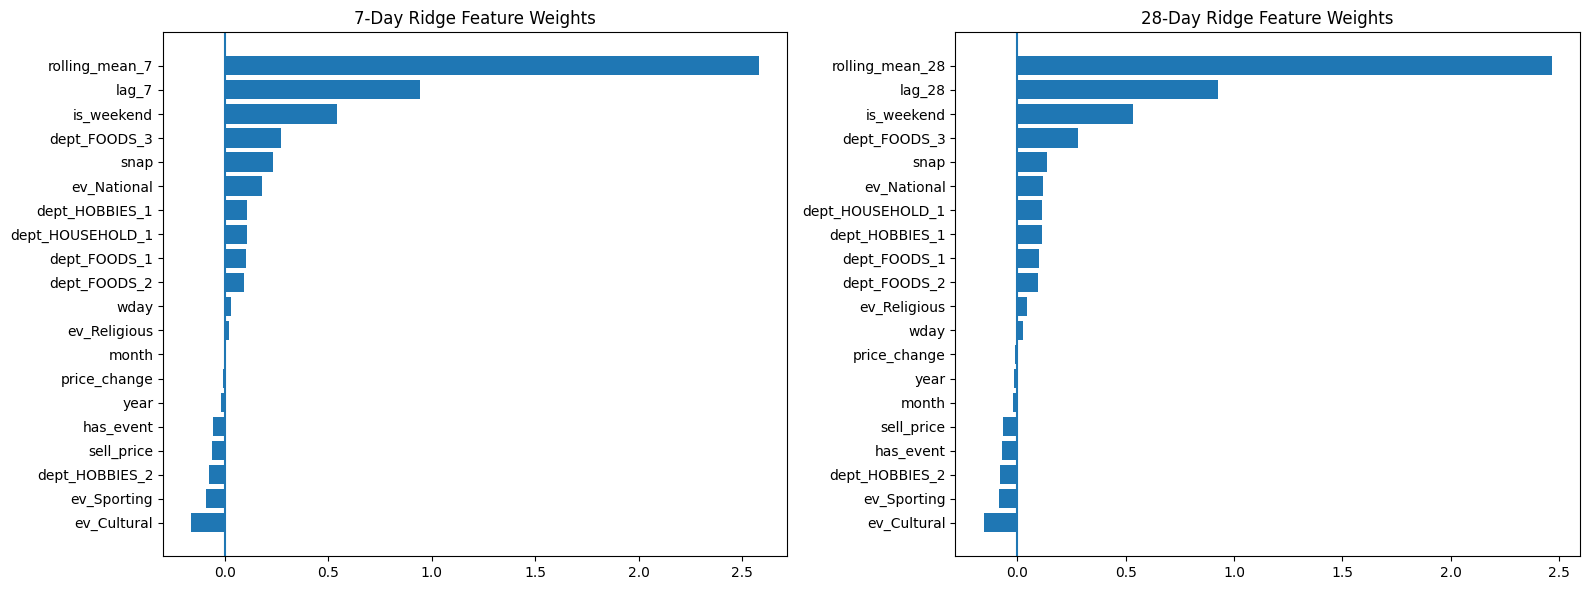

In [ ]:
# Train Ridge models using alpha = 100
model_7 = Ridge(alpha=100)
model_7.fit(X_train_7, y_train_7)
model_28 = Ridge(alpha=100)
model_28.fit(X_train_28, y_train_28)
# Get feature names and their weights
coef_7 = pd.DataFrame({
    "Feature": X_train_7.columns,
    "Weight": model_7.coef_
}).sort_values("Weight")

coef_28 = pd.DataFrame({
    "Feature": X_train_28.columns,
    "Weight": model_28.coef_
}).sort_values("Weight")
# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# 7-Day feature weights
axes[0].barh(coef_7["Feature"], coef_7["Weight"])
axes[0].axvline(0)
axes[0].set_title("7-Day Ridge Feature Weights")
# 28-Day feature weights
axes[1].barh(coef_28["Feature"], coef_28["Weight"])
axes[1].axvline(0)
axes[1].set_title("28-Day Ridge Feature Weights")
# Display charts
plt.tight_layout()
plt.show()

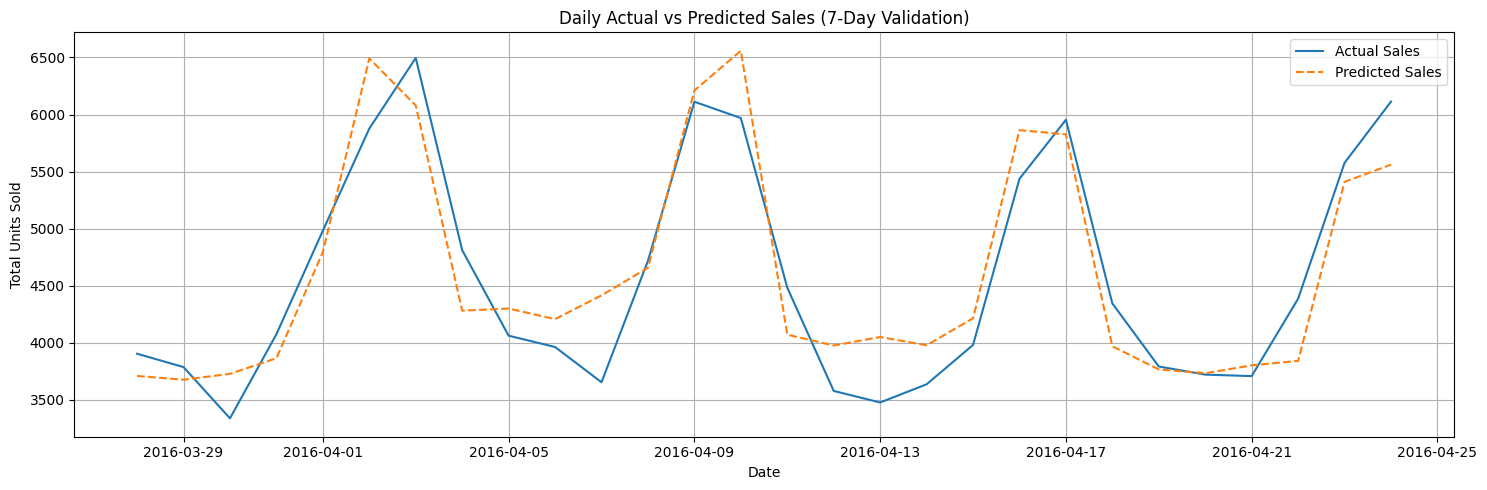

In [ ]:
# Prepare validation data
val_plot = val_7[["date", "sales"]].copy()
# Get Ridge predictions
val_plot["predicted"] = model_7.predict(X_val_7)
# Remove negative predictions
val_plot["predicted"] = np.maximum(val_plot["predicted"], 0)
# Calculate total actual and predicted sales for each day
daily_agg = val_plot.groupby("date")[["sales", "predicted"]].sum().reset_index()
# Plot actual vs predicted sales
plt.figure(figsize=(15, 5))
plt.plot(daily_agg["date"], daily_agg["sales"], label="Actual Sales")
plt.plot(daily_agg["date"], daily_agg["predicted"], label="Predicted Sales", linestyle="--")
plt.title("Daily Actual vs Predicted Sales (7-Day Validation)")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()